# 03 – HMM sur les rendements réels du Bitcoin + prédiction du prochain régime
Données : **BTCUSDT**, bougies de **8 h** (1 jour = 3 lignes), préparées par le notebook `01_donnees`. Observations : rendement log et volatilité. Étapes : chargement des fichiers train/test → choix de N (AIC/BIC) → interprétation → **prédiction sans look-ahead bias**.

**Exécuter d'abord `01_donnees.ipynb`** : ce notebook relit ses fichiers (même features, même découpage, même standardisation).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from hmmlearn.hmm import GaussianHMM
from scipy.stats import multivariate_normal
np.set_printoptions(precision=4, suppress=True)

DOSSIER  = "../data/btcusdt"   # fichiers produits par 01_donnees.ipynb
PAR_JOUR = 3                   # bougies de 8 h : 1 jour = 3 lignes

## 1. Chargement des données préparées (notebook 01)
`X_train` / `X_test` sont déjà standardisés avec un scaler ajusté sur le train seulement. Le fichier de features complet sert à retrouver le prix (`Close`) et le rendement brut pour l'évaluation.

In [2]:
X_train_df = pd.read_csv(f"{DOSSIER}_X_train.csv", index_col=0, parse_dates=True)
X_test_df  = pd.read_csv(f"{DOSSIER}_X_test.csv",  index_col=0, parse_dates=True)
feat       = pd.read_csv(f"{DOSSIER}_features.csv", index_col=0, parse_dates=True)
scaler     = joblib.load(f"{DOSSIER}_scaler.joblib")

colonnes = list(X_train_df.columns)
assert colonnes == list(scaler.feature_names_in_) and {"rendement", "volatilite"} <= set(colonnes)
X_train, X_test = X_train_df.values, X_test_df.values
test = feat.loc[X_test_df.index]                     # prix et features brutes de la période de test
print(f"Features : {colonnes}")
print(f"train : {X_train_df.index[0]} -> {X_train_df.index[-1]} ({len(X_train)} lignes = {len(X_train) // PAR_JOUR} jours)")
print(f"test  : {X_test_df.index[0]} -> {X_test_df.index[-1]} ({len(X_test)} lignes = {len(X_test) // PAR_JOUR} jours)")

Features : ['rendement', 'volatilite']
train : 2017-09-06 00:00:00 -> 2024-02-01 16:00:00 (7014 lignes = 2338 jours)
test  : 2024-02-02 00:00:00 -> 2026-10-31 16:00:00 (3009 lignes = 1003 jours)


## 2. Choix du nombre d'états N (AIC / BIC)
Nombre de paramètres d'un HMM gaussien à covariance pleine, avec `d` variables : `k = (N−1) + N(N−1) + N·d + N·d(d+1)/2`.

,logL,k,AIC,BIC
N,,,,
2,-14948.9,13,29923.9,30013.0
3,-11670.1,23,23386.3,23544.0
4,-9495.8,35,19061.6,19301.5
5,-8115.2,49,16328.4,16664.3


N optimal selon BIC : 5 | selon AIC : 5


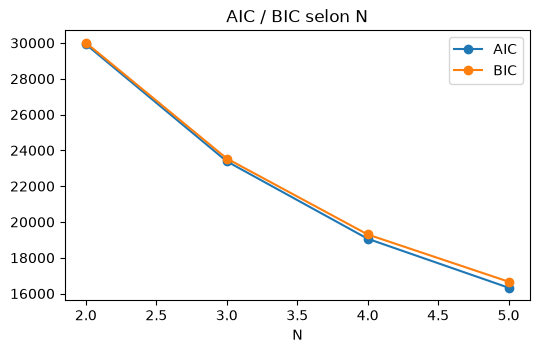

In [3]:
def meilleur_modele(X, N, n_init=8):
    best, best_ll = None, -np.inf
    for seed in range(n_init):                      # plusieurs initialisations (optimum local)
        m = GaussianHMM(n_components=N, covariance_type="full", n_iter=300, tol=1e-4, random_state=seed)
        try:
            m.fit(X); ll = m.score(X)
        except Exception:
            continue
        if ll > best_ll: best, best_ll = m, ll
    return best, best_ll

d, n = X_train.shape[1], len(X_train)
lignes, modeles = [], {}
for N in range(2, 6):
    m, ll = meilleur_modele(X_train, N)
    k = (N-1) + N*(N-1) + N*d + N*d*(d+1)//2
    lignes.append({"N": N, "logL": ll, "k": k, "AIC": 2*k - 2*ll, "BIC": k*np.log(n) - 2*ll})
    modeles[N] = m
tab = pd.DataFrame(lignes).set_index("N"); display(tab.round(1))
N_BIC = int(tab["BIC"].idxmin()); N_AIC = int(tab["AIC"].idxmin())
print("N optimal selon BIC :", N_BIC, "| selon AIC :", N_AIC)
tab[["AIC", "BIC"]].plot(marker="o", figsize=(6, 3.5), title="AIC / BIC selon N"); plt.show()

## 3. Modèle retenu et interprétation économique
Le sujet demande 3 états (haussier, baissier, panique). On prend `N = 3` pour l'interprétation et on compare avec le choix du BIC dans le rapport. Les états sont **triés par rendement moyen** pour que « 0 = le plus baissier ».

In [4]:
N = 3
model = modeles[N]
i_rend, i_vol = colonnes.index("rendement"), colonnes.index("volatilite")
ordre = np.argsort(model.means_[:, i_rend])          # tri par rendement moyen croissant
mu_brut = scaler.inverse_transform(model.means_)[ordre]
A = model.transmat_[np.ix_(ordre, ordre)]
pi0 = model.startprob_[ordre]
covs = model.covars_[ordre]; means = model.means_[ordre]

resume = pd.DataFrame(mu_brut, columns=[f"{c} moyen(ne)" for c in colonnes])
resume["durée moyenne (bougies)"] = 1 / (1 - np.diag(A))
resume["durée moyenne (jours)"]  = resume["durée moyenne (bougies)"] / PAR_JOUR
resume.index = ["État 0 (rendement le plus bas)", "État 1", "État 2 (rendement le plus haut)"]
display(resume.round(5))
print("Matrice de transition (états triés) :\n", A.round(3))

,rendement moyen(ne),volatilite moyen(ne),durée moyenne (bougies),durée moyenne (jours)
État 0 (rendement le plus bas),-0.00019,0.03551,72.26071,24.08690
État 1,0.00033,0.01207,112.93803,37.64601
État 2 (rendement le plus haut),0.00057,0.02016,84.43096,28.14365


Matrice de transition (états triés) :
 [[0.986 0.001 0.013]
 [0.003 0.991 0.006]
 [0.003 0.009 0.988]]


In [5]:
# Étiquetage automatique : volatilité la plus forte = Panique ; parmi les 2 autres, rendement le plus haut = Haussier ; reste = Baissier
vol = mu_brut[:, i_vol]
etiquettes = {}
etiquettes[int(np.argmax(vol))] = "Panique"
reste = [i for i in range(3) if i not in etiquettes]
etiquettes[reste[int(np.argmax(mu_brut[reste, i_rend]))]] = "Haussier"
etiquettes[[i for i in range(3) if i not in etiquettes][0]] = "Baissier"
NOMS = [etiquettes[i] for i in range(3)]
print("Étiquettes :", dict(enumerate(NOMS)), "(à vérifier à la main dans le rapport)")

Étiquettes : {0: 'Panique', 1: 'Baissier', 2: 'Haussier'} (à vérifier à la main dans le rapport)


## 4. Prédiction **sans look-ahead bias** (filtrage forward)
`predict_proba` de hmmlearn utilise passé **et futur** de la série (lissage). Pour le trading, il faut le **filtre forward** : `P(S_t | x_1..x_t)`. Puis la prédiction pour la bougie suivante (8 h plus tard) : `P(S_{t+1}) = filtre_t · A`.

In [6]:
def filtre_forward(X, pi0, A, means, covs):
    T, N = len(X), len(pi0)
    emis = np.column_stack([multivariate_normal(means[i], covs[i], allow_singular=True).pdf(X) for i in range(N)])
    F = np.zeros((T, N))
    f = pi0 * emis[0]; F[0] = f / f.sum()
    for t in range(1, T):
        f = (F[t-1] @ A) * emis[t]; F[t] = f / f.sum()
    return F

X_tout  = np.vstack([X_train, X_test])
F       = filtre_forward(X_tout, pi0, A, means, covs)   # modèle appris sur le train seulement
F_test  = F[len(X_train):]
P_next  = F_test @ A                                    # probabilité du régime à t+1
regime_pred = P_next.argmax(axis=1)

res = test.copy()
res["regime_actuel"]  = [NOMS[i] for i in F_test.argmax(axis=1)]
res["regime_predit"]  = [NOMS[i] for i in regime_pred]
res["rendement_suivant"] = res["rendement"].shift(-1)
res = res.iloc[:-1]
display(res[["rendement", "regime_actuel", "regime_predit"]].tail(6))

,rendement,regime_actuel,regime_predit
Date,,,
2026-10-29 16:00:00,-0.047400,Baissier,Baissier
2026-10-30 00:00:00,0.002478,Baissier,Baissier
2026-10-30 08:00:00,-0.007232,Baissier,Baissier
2026-10-30 16:00:00,-0.003268,Baissier,Baissier
2026-10-31 00:00:00,-0.000165,Baissier,Baissier
2026-10-31 08:00:00,0.003433,Baissier,Baissier


In [7]:
# Évaluation : le régime prédit renseigne-t-il sur le rendement de la bougie suivante ?
stats = res.groupby("regime_predit")["rendement_suivant"].agg(["count", "mean", "std"])
stats["rendement annualisé"] = stats["mean"] * PAR_JOUR * 365
display(stats.round(5))

# Comparaison avec la méthode naïve « le régime de la bougie suivante = le régime actuel »
naif = (res["regime_actuel"] == res["regime_predit"]).mean()
print(f"Le régime prédit = le régime actuel dans {naif:.1%} des cas (persistance des régimes)")

,count,mean,std,rendement annualisé
regime_predit,,,,
Baissier,2421,0.00007,0.01292,0.07406
Haussier,580,0.00054,0.01594,0.59436
Panique,7,0.01565,0.02651,17.13559


Le régime prédit = le régime actuel dans 100.0% des cas (persistance des régimes)


**Lecture.** Si ce pourcentage est proche de 100 %, c'est normal : la diagonale de A est très grande (régimes persistants), donc le régime le plus probable à la bougie suivante est presque toujours le régime actuel. L'apport du HMM n'est pas de changer le régime prédit, mais de donner la **probabilité de changer de régime** : `P(changement) = 1 − P(S_{t+1} = régime actuel)`. On vérifie qu'elle est bien calibrée.

In [8]:
idx_act = F_test.argmax(axis=1)[:-1]
p_chg = 1 - P_next[:-1][np.arange(len(idx_act)), idx_act]          # probabilité prédite de changer de régime
chg_reel = (F_test.argmax(axis=1)[1:] != idx_act).astype(int)      # changement observé à t+1
calib = pd.DataFrame({"p_chg": p_chg, "reel": chg_reel})
calib["classe"] = pd.qcut(calib["p_chg"], 4, duplicates="drop")
display(calib.groupby("classe", observed=True).agg(proba_predite=("p_chg", "mean"), frequence_reelle=("reel", "mean"), n=("reel", "size")).round(4))

,proba_predite,frequence_reelle,n
classe,,,
"(0.007869999999999999, 0.00888]",0.0089,0.0000,752
"(0.00888, 0.00899]",0.0089,0.0027,752
"(0.00899, 0.0121]",0.0098,0.0080,752
"(0.0121, 0.639]",0.0595,0.0359,752


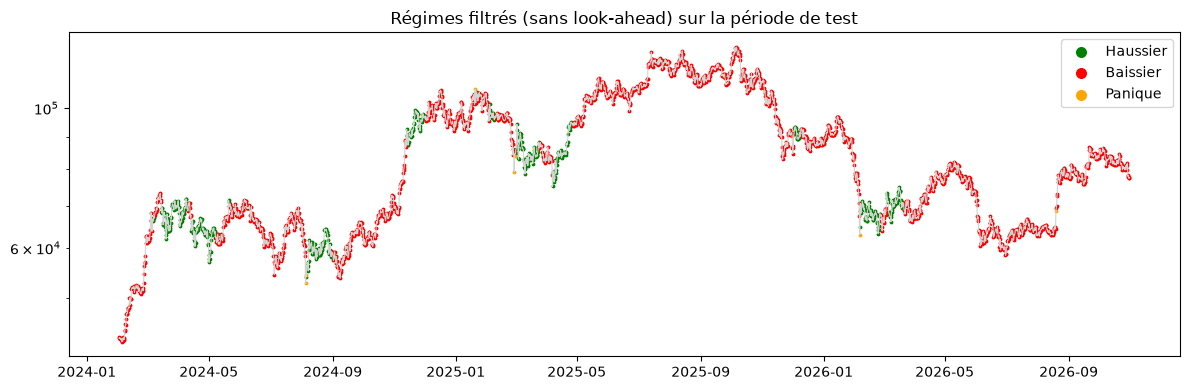

In [9]:
# Graphique : prix colorié par régime (test)
couleurs = {"Haussier": "green", "Baissier": "red", "Panique": "orange"}
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(res.index, res["Close"], color="lightgrey", lw=0.8)
for nom, col in couleurs.items():
    sel = res["regime_actuel"] == nom
    ax.scatter(res.index[sel], res["Close"][sel], s=3, color=col, label=nom)
ax.set_yscale("log"); ax.legend(markerscale=4); ax.set_title("Régimes filtrés (sans look-ahead) sur la période de test")
plt.tight_layout(); plt.savefig("../results/regimes_test.png", dpi=150); plt.show()